In [2]:
from pathlib import Path

import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
DATA_PATH = Path("../data/raw/seg_train")

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 17034 files belonging to 6 classes.
Using 13628 files for training.


In [6]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 17034 files belonging to 6 classes.
Using 3406 files for validation.


In [8]:
half = len(val_ds) // 2

test_ds = val_ds.take(half)
val_ds = val_ds.skip(half)

In [9]:
class_names = train_ds.class_names

print(class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [10]:
NUM_CLASSES = len(class_names)

print(NUM_CLASSES)

6


In [11]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [12]:
model = tf.keras.Sequential([
    
    tf.keras.Input(shape=(150, 150, 3)),
    
    data_augmentation,
    
    tf.keras.layers.Rescaling(1./255),
    
    tf.keras.layers.Conv2D(
        32,
        3,
        activation="relu"
    ),
    
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(
        64,
        3,
        activation="relu"
    ),
    
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(
        128,
        3,
        activation="relu"
    ),
    
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Flatten(),
    
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),
    
    tf.keras.layers.Dropout(0.5),
    
    tf.keras.layers.Dense(
        6,
        activation="softmax"
    )
])

In [13]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/best_model.keras",
    monitor="val_loss",
    save_best_only=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=32,
    callbacks=[
        early_stopping,
        checkpoint,
        reduce_lr
    ]
)

Epoch 1/32


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


426/426 ━━━━━━━━━━━━━━━━━━━━ 76s 171ms/step - accuracy: 0.5418 - loss: 1.1695 - val_accuracy: 0.5603 - val_loss: 1.1401 - learning_rate: 0.0010
Epoch 2/32
426/426 ━━━━━━━━━━━━━━━━━━━━ 72s 169ms/step - accuracy: 0.6367 - loss: 0.9659 - val_accuracy: 0.7080 - val_loss: 0.7669 - learning_rate: 0.0010
Epoch 3/32
426/426 ━━━━━━━━━━━━━━━━━━━━ 82s 168ms/step - accuracy: 0.6953 - loss: 0.8268 - val_accuracy: 0.7447 - val_loss: 0.6878 - learning_rate: 0.0010
Epoch 4/32
426/426 ━━━━━━━━━━━━━━━━━━━━ 73s 171ms/step - accuracy: 0.7207 - loss: 0.7727 - val_accuracy: 0.7660 - val_loss: 0.6493 - learning_rate: 0.0010
Epoch 5/32
426/426 ━━━━━━━━━━━━━━━━━━━━ 72s 169ms/step - accuracy: 0.7466 - loss: 0.7146 - val_accuracy: 0.7730 - val_loss: 0.6204 - learning_rate: 0.0010
Epoch 6/32
426/426 ━━━━━━━━━━━━━━━━━━━━ 72s 168ms/step - accuracy: 0.7523 - loss: 0.6803 - val_accuracy: 0.7730 - val_loss: 0.6294 - learning_rate: 0.0010
Epoch 7/32
426/426 ━━━━━━━━━━━━━━━━━━━━ 73s 170ms/step - accuracy: 0.7699 - loss:

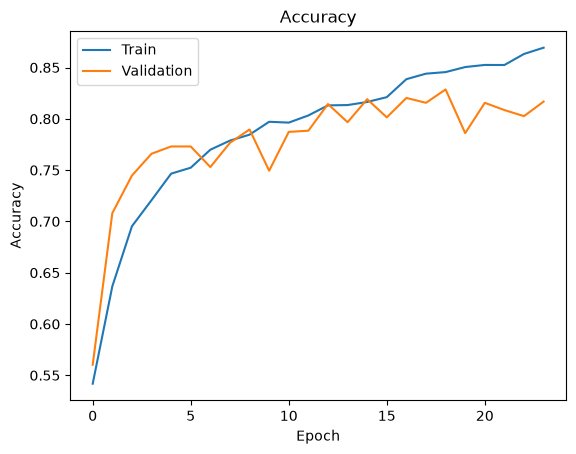

In [16]:
plt.plot(
    history.history["accuracy"],
    label="Train"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.title("Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()

plt.show()

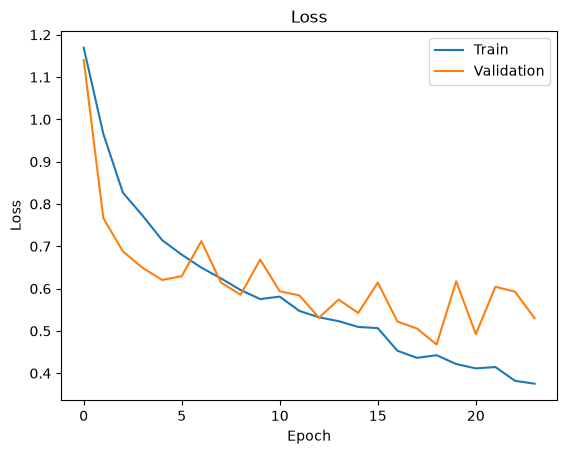

27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8085 - loss: 0.5093
Validation accuracy: 0.8085106611251831
